# 24. LR 강화 (1차): 기존 변이 유형 피처 조합으로 LR을 바꿔 14 섞기와 비교

## 배경
- 14 섞기(XGB 0.7 + LR 0.3)가 LB 0.32466으로 현재 최고 → 섞기 효과는 대부분 LR에서 나옴 (XGB와 예측 불일치가 가장 큼)
- 지금 LR은 `any`(유전자별 변이 유무)만 사용 → LR 쪽 정보를 늘리면 섞기 점수가 오를 수 있음
- LR은 **개수 피처(stats)를 쓰지 않으므로** test 환자 변이 수가 2배인 차이에 덜 흔들림 (11/11 회의 목표와 같은 방향)
- 치환 토큰(은지님 함수 PR 예정)을 넣기 전에, 기존 피처(trunc, nonsilent, silent) 조합부터 확인

## 가설
- H24a: LR 피처를 `any`에서 변이 유형 정보(trunc, silent 분리 등)가 있는 조합으로 바꾸면, XGB 0.7 + LR 0.3 섞기가 14보다 오른다

## 검증 방법
- XGB는 14와 같은 모델(10 설정, any + stats) 그대로, **LR 쪽 피처만 바꿈**
- LR 설정 고정: C=0.1, class_weight='balanced' (05·14와 동일)
- 섞는 비율 고정: XGB 0.7 + LR 0.3 (14와 동일, 다시 고르지 않음 → 비율 튜닝으로 인한 낙관 없음)
- 비교: 같은 fold(`get_folds`, seed 42)에서 fold별 Macro F1을 14와 비교
- **채택 기준: 5개 fold 중 4개 이상에서 14보다 높을 때만** 단톡 공유 → 제출 후보
- 진단(채택 판단에는 안 씀): test 예측이 14와 다른 환자 비율을 OOF에서의 비율과 비교, COAD 예측 비율
- test는 예측에만 사용. 제출 파일은 설아님 Windows 데스크탑에서만 생성 (마지막 셀 `SAVE`)


In [1]:
import sys; sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import time, numpy as np, pandas as pd, xgboost as xgb
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from src.config import SEED
from src.data import load_data, get_gene_cols
from src.features import mutation_features
from src.validation import seed_everything, encode_target, get_folds, run_cv, macro_f1, save_submission

seed_everything()
train, test, submission = load_data()          # 정규화 + 이소폼 중복 제거 (10·14와 동일)
genes = get_gene_cols(train)
y, le = encode_target(train)
FOLDS = get_folds(y)
F_tr, F_te = mutation_features(train, genes), mutation_features(test, genes)
print({k: v.shape for k, v in F_tr.items()})

{'any': (6201, 4384), 'nonsilent': (6201, 4384), 'silent': (6201, 4384), 'trunc': (6201, 4384), 'stats': (6201, 9)}


#### XGB (14와 동일) + LR 피처 조합
- XGB 확률은 캐시(`submissions/cache24/XGB.npz`)로 저장 → 다시 실행할 때는 학습 없이 불러옴 (약 5분 절약)
- LR 피처 조합 7가지: `any`는 14의 LR과 같음 (기준)

In [2]:
CACHE = Path('../submissions/cache24'); CACHE.mkdir(parents=True, exist_ok=True)

class BalancedXGB(xgb.XGBClassifier):
    def fit(self, X, y, **kw):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kw)

XGB10 = dict(n_estimators=200, learning_rate=0.1, max_depth=3, colsample_bytree=0.3,
             tree_method='hist', eval_metric='mlogloss', random_state=SEED, n_jobs=-1)
lr = lambda: LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced', random_state=SEED)

def cached(name, make, X, X_te):
    p = CACHE / f'{name}.npz'
    if p.exists():
        z = np.load(p); return z['oof'], z['test']
    t = time.time()
    r = run_cv(make, X, y, X_te, folds=FOLDS, verbose=False)
    np.savez(p, oof=r['oof_proba'], test=r['test_proba'])
    print(f'  {name}: 학습 {time.time() - t:.0f}s')
    return r['oof_proba'], r['test_proba']

cat = lambda parts, F: pd.concat([F[p] for p in parts], axis=1)
XGB_oof, XGB_te = cached('XGB', lambda: BalancedXGB(**XGB10), cat(['any', 'stats'], F_tr), cat(['any', 'stats'], F_te))

LR_SETS = {   # 이름: 피처 묶음
    'any (14 기준)':          ['any'],
    'nonsilent':              ['nonsilent'],
    'nonsilent + silent':     ['nonsilent', 'silent'],
    'any + silent':           ['any', 'silent'],
    'any + trunc':            ['any', 'trunc'],
    'nonsilent + trunc':      ['nonsilent', 'trunc'],
    'any + trunc + silent':   ['any', 'trunc', 'silent'],
}
LR_oof, LR_te = {}, {}
for name, parts in LR_SETS.items():
    key = 'LR_' + '_'.join(parts)
    LR_oof[name], LR_te[name] = cached(key, lr, cat(parts, F_tr).astype('float32'), cat(parts, F_te).astype('float32'))
print('완료')

완료


#### 비교: LR 단독 / XGB 0.7 + LR 0.3 섞기 (fold별, 14 대비)

In [3]:
fold_scores = lambda P: np.array([macro_f1(y[va], P[va].argmax(1)) for _, va in FOLDS])
blend = lambda name, which='oof': 0.7 * (XGB_oof if which == 'oof' else XGB_te) + 0.3 * (LR_oof[name] if which == 'oof' else LR_te[name])

base = fold_scores(blend('any (14 기준)'))
rows = []
for name in LR_SETS:
    s_lr, s_bl = fold_scores(LR_oof[name]), fold_scores(blend(name))
    d = s_bl - base
    rows.append({'LR 피처': name, 'LR 단독 CV': s_lr.mean(), '섞기 CV': s_bl.mean(), '섞기 std': s_bl.std(),
                 '14 대비': d.mean(), '14보다 높은 fold': f'{(d > 0).sum()}/5',
                 '채택': '✅' if name != 'any (14 기준)' and (d > 0).sum() >= 4 else ''})
res = pd.DataFrame(rows).set_index('LR 피처')
print(f'XGB 단독 CV {fold_scores(XGB_oof).mean():.4f} | 14 섞기 fold별 {base.round(4)}')
res.round(4)

XGB 단독 CV 0.4154 | 14 섞기 fold별 [0.4119 0.423  0.4378 0.4098 0.4261]


,LR 단독 CV,섞기 CV,섞기 std,14 대비,14보다 높은 fold,채택
LR 피처,,,,,,
any (14 기준),0.3818,0.4217,0.0102,0.0000,0/5,
nonsilent,0.3595,0.4207,0.0087,-0.0010,2/5,
nonsilent + silent,0.3701,0.4187,0.0084,-0.0030,2/5,
any + silent,0.3789,0.4199,0.0090,-0.0019,1/5,
any + trunc,0.3920,0.4220,0.0111,0.0002,4/5,✅
nonsilent + trunc,0.3660,0.4251,0.0069,0.0033,4/5,✅
any + trunc + silent,0.3887,0.4216,0.0096,-0.0002,2/5,


#### 진단 (채택 판단에는 사용하지 않음)
- 14와 예측이 다른 환자 비율: OOF(검증 데이터)와 test에서 비슷하면 → test에서만 이상하게 움직이지 않음
- test COAD 예측 비율 (11/11 회의: 14 = 17.3%, select6 = 22.5%)

In [4]:
t14 = blend('any (14 기준)', 'test'); o14 = blend('any (14 기준)')
diag = []
for name in LR_SETS:
    o, t = blend(name), blend(name, 'test')
    diag.append({'LR 피처': name,
                 '14와 다른 환자 (OOF)': (o.argmax(1) != o14.argmax(1)).mean() * 100,
                 '14와 다른 환자 (test)': (t.argmax(1) != t14.argmax(1)).mean() * 100,
                 'test COAD %': (le.inverse_transform(t.argmax(1)) == 'COAD').mean() * 100})
pd.DataFrame(diag).set_index('LR 피처').round(1)

,14와 다른 환자 (OOF),14와 다른 환자 (test),test COAD %
LR 피처,,,
any (14 기준),0.0,0.0,17.1
nonsilent,3.3,5.3,18.3
nonsilent + silent,2.9,4.7,18.1
any + silent,1.2,2.5,16.8
any + trunc,1.3,4.1,19.7
nonsilent + trunc,3.5,7.2,20.7
any + trunc + silent,2.0,5.2,19.5


#### fold별 점수 그래프 (슬라이드용)

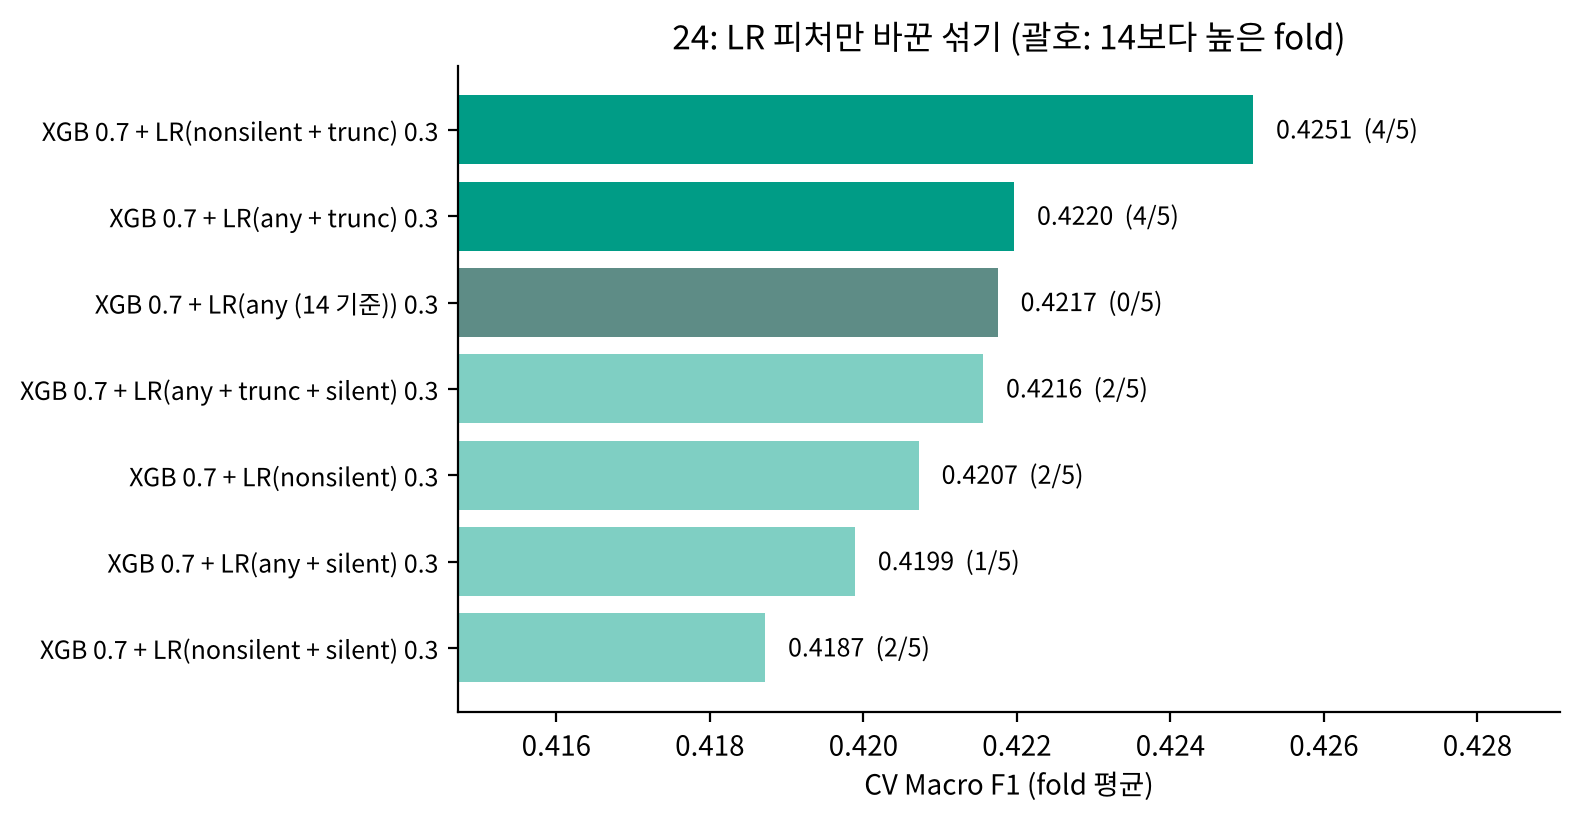

In [5]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR'] if f in _have), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(8, 4.2))
order = res.sort_values('섞기 CV').index
cols = ['#5E8C86' if n == 'any (14 기준)' else ('#009C86' if res.loc[n, '채택'] else '#7FCFC3') for n in order]
ax.barh(range(len(order)), res.loc[order, '섞기 CV'], color=cols)
for i, n in enumerate(order):
    ax.text(res.loc[n, '섞기 CV'] + 0.0003, i, f"{res.loc[n, '섞기 CV']:.4f}  ({res.loc[n, '14보다 높은 fold']})", va='center', fontsize=9)
ax.set_yticks(range(len(order)), [f'XGB 0.7 + LR({n}) 0.3' for n in order], fontsize=9)
ax.set_xlim(res['섞기 CV'].min() - 0.004, res['섞기 CV'].max() + 0.004)
ax.set_xlabel('CV Macro F1 (fold 평균)'); ax.set_title('24: LR 피처만 바꾼 섞기 (괄호: 14보다 높은 fold)')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('../submissions/24_lr_blend.png', dpi=150); plt.show()

#### 제출 파일 (채택된 조합만, 설아님 Windows 데스크탑에서 `SAVE = True`로 실행)

In [6]:
SAVE = False   # 팀 규칙: 제출 파일은 Windows 데스크탑에서만 생성
adopted = [n for n in LR_SETS if res.loc[n, '채택']]
print('채택:', adopted or '없음')
if SAVE:
    for name in adopted:
        tag = name.replace(' + ', '_').replace(' ', '')
        p = save_submission(submission, blend(name, 'test'), le, name=f'blend_XGB0.7_LR-{tag}0.3', cv_score=res.loc[name, '섞기 CV'])
        print('저장:', p)

채택: ['any + trunc', 'nonsilent + trunc']


## 결과
| LR 피처 (XGB 0.7 + LR 0.3) | LR 단독 CV | 섞기 CV | 14 대비 | 14보다 높은 fold | test에서 14와 다른 환자 (OOF) | test COAD % |
| :-- | :-: | :-: | :-: | :-: | :-: | :-: |
| any (14 기준) | 0.3818 | 0.4217 | — | — | — | 17.1 |
| nonsilent | 0.3595 | 0.4207 | −0.0010 | 2/5 | 5.3% (3.3%) | 18.3 |
| nonsilent + silent | 0.3701 | 0.4187 | −0.0030 | 2/5 | 4.7% (2.9%) | 18.1 |
| any + silent | 0.3789 | 0.4199 | −0.0019 | 1/5 | 2.5% (1.2%) | 16.8 |
| any + trunc | 0.3920 | 0.4220 | +0.0002 | 4/5 | 4.1% (1.3%) | 19.7 |
| **nonsilent + trunc** | 0.3660 | **0.4251** | **+0.0033** | **4/5** | 7.2% (3.5%) | 20.7 |
| any + trunc + silent | 0.3887 | 0.4216 | −0.0002 | 2/5 | 5.2% (2.0%) | 19.5 |

- 기준 숫자는 이 실행 환경(Linux) XGB 기준. 14 섞기 0.4217은 16 노트북의 같은 기준(fold 평균) 값과 같음
- silent를 따로 넣는 조합은 모두 하락 → 침묵 변이 분리는 LR에서도 도움 안 됨 (08과 같은 결론)
- **trunc가 들어간 조합만 오름**. 특히 nonsilent + trunc는 LR 단독은 가장 낮은 편(0.3660)인데 섞기는 가장 높음 → XGB와 다르게 틀리는 정도가 커서 섞기에 유리
- any + trunc는 4/5지만 평균 +0.0002로 사실상 차이 없음

**진단 (채택 판단에는 안 씀)**
- trunc가 들어간 LR은 test COAD 예측이 늘어남 (17.1% → 19.7~20.7%). 20번에서 본 대로 test에 APC 절단 변이가 많아서(24.2%), trunc 피처가 COAD 쪽으로 밀어줌
- 14와 다른 환자 비율이 test에서 OOF보다 약 2배 (7.2% vs 3.5%) → test에서 더 크게 움직임

## 결론
- **H24a 부분 채택**: LR(nonsilent + trunc)로 바꾼 섞기가 CV +0.0033, 4/5 fold로 채택 기준 통과
- ⚠️ 다만 11/11 select6(LR_trunc 비중 큼)이 LB에서 떨어졌고, 이 조합도 COAD 예측을 20.7%로 올림 → **LB 효과는 불확실**. 제출 후보로 공유하되 우선순위는 낮게 두는 것을 제안
- 다음(24 2차): 은지님 치환 함수(PR #29)로 치환 토큰을 LR에 추가 → trunc 없이도 오르는지 확인 (COAD 쏠림 없이 LR을 강화할 수 있는지)
- 제출 파일은 설아님 Windows 데스크탑에서 `SAVE = True`로 생성
